# Notebook 2 — Feature Engineering
Cleaning, encoding, and creating new features for model training

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.io as pio
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings('ignore')

pio.renderers.default = "notebook"
pd.set_option('display.max_columns', 50)

## 1. Load & Filter Raw Data

In [2]:
CSV_PATH = '../accepted_2007_to_2018Q4.csv'
SAMPLE_SIZE = 200_000

RAW_FEATURES = [
    'loan_amnt', 'int_rate', 'installment', 'annual_inc', 'dti',
    'delinq_2yrs', 'fico_range_low', 'fico_range_high', 'open_acc', 'pub_rec',
    'revol_bal', 'revol_util', 'total_acc', 'mort_acc', 'pub_rec_bankruptcies',
    'purpose', 'home_ownership', 'verification_status', 'term',
    'grade', 'sub_grade', 'inq_last_6mths', 'emp_length', 'earliest_cr_line',
    'loan_status',
]

df_raw = pd.read_csv(CSV_PATH, usecols=RAW_FEATURES, low_memory=False)
df = df_raw[df_raw['loan_status'].isin(['Fully Paid', 'Charged Off'])].copy()
df = df.sample(SAMPLE_SIZE, random_state=42).reset_index(drop=True)
print(f'Shape: {df.shape}')
df.head(3)

Shape: (200000, 25)


,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,loan_status,purpose,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,mort_acc,pub_rec_bankruptcies
0,8000.0,36 months,7.69,249.55,A,A4,1 year,MORTGAGE,80000.0,Not Verified,Fully Paid,debt_consolidation,8.73,0.0,Sep-2000,680.0,684.0,1.0,11.0,0.0,7141.0,39.9,30.0,6.0,0.0
1,12000.0,36 months,15.05,416.28,C,C4,< 1 year,OWN,36000.0,Verified,Fully Paid,debt_consolidation,17.86,0.0,Oct-2005,660.0,664.0,1.0,7.0,0.0,4374.0,58.3,13.0,0.0,0.0
2,8000.0,36 months,12.99,269.52,C,C1,2 years,RENT,26000.0,Source Verified,Fully Paid,debt_consolidation,27.98,1.0,Sep-2002,680.0,684.0,0.0,11.0,1.0,4837.0,56.9,15.0,0.0,1.0


## 2. Clean String Columns

In [3]:
# interest rate: '12.99%' → 12.99
df['int_rate'] = df['int_rate'].astype(str).str.replace('%', '').astype(float)

# term: ' 36 months' → 36
df['term'] = df['term'].astype(str).str.strip().str.replace(' months', '').astype(int)

# revolving utilization: '45.3%' → 45.3
df['revol_util'] = pd.to_numeric(
    df['revol_util'].astype(str).str.replace('%', ''), errors='coerce'
)

print('int_rate sample:', df['int_rate'].head(3).values)
print('term sample    :', df['term'].head(3).values)

int_rate sample: [ 7.69 15.05 12.99]
term sample    : [36 36 36]


## 3. Handle Null Values

In [4]:
before = df.isnull().sum().sum()

df['mort_acc']            = df['mort_acc'].fillna(0)
df['pub_rec_bankruptcies']= df['pub_rec_bankruptcies'].fillna(0)
df['inq_last_6mths']      = df['inq_last_6mths'].fillna(0)
df['emp_length']          = df['emp_length'].fillna('Unknown')

# credit history: parse date, convert to years from 2018-01-01
df['earliest_cr_line'] = pd.to_datetime(df['earliest_cr_line'], format='%b-%Y', errors='coerce')
df['earliest_cr_line'] = (pd.Timestamp('2018-01-01') - df['earliest_cr_line']).dt.days / 365.25
df['earliest_cr_line'] = df['earliest_cr_line'].fillna(df['earliest_cr_line'].median())

df.dropna(inplace=True)
after = df.isnull().sum().sum()
print(f'Nulls before: {before}  |  after: {after}')
print(f'Rows remaining: {len(df):,}')

Nulls before: 19106  |  after: 0
Rows remaining: 199,816


## 4. Ordinal Encoding — Grade, Sub-Grade, Employment

In [5]:
GRADE_ORDER     = ['A','B','C','D','E','F','G']
SUB_GRADE_ORDER = [f'{g}{n}' for g in GRADE_ORDER for n in range(1,6)]
EMP_ORDER       = [
    '< 1 year','1 year','2 years','3 years','4 years',
    '5 years','6 years','7 years','8 years','9 years','10+ years','Unknown'
]

grade_map     = {g: i for i, g in enumerate(GRADE_ORDER)}
sub_grade_map = {sg: i for i, sg in enumerate(SUB_GRADE_ORDER)}
emp_map       = {e: i for i, e in enumerate(EMP_ORDER)}

df['grade']     = df['grade'].map(grade_map).fillna(6).astype(int)
df['sub_grade'] = df['sub_grade'].map(sub_grade_map).fillna(34).astype(int)
df['emp_length']= df['emp_length'].map(emp_map).fillna(11).astype(int)

print('Grade sample (0=A … 6=G):')
print(df['grade'].value_counts().sort_index())

Grade sample (0=A … 6=G):
grade
0    35032
1    58200
2    56600
3    30045
4    13813
5     4807
6     1319
Name: count, dtype: int64


## 5. Label Encoding — Nominal Categoricals

In [6]:
CAT_COLS = ['purpose', 'home_ownership', 'verification_status']
label_encoders = {}

for col in CAT_COLS:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col].astype(str))
    label_encoders[col] = le
    print(f'{col}: {dict(zip(le.classes_, le.transform(le.classes_)))}')

purpose: {'car': np.int64(0), 'credit_card': np.int64(1), 'debt_consolidation': np.int64(2), 'educational': np.int64(3), 'home_improvement': np.int64(4), 'house': np.int64(5), 'major_purchase': np.int64(6), 'medical': np.int64(7), 'moving': np.int64(8), 'other': np.int64(9), 'renewable_energy': np.int64(10), 'small_business': np.int64(11), 'vacation': np.int64(12), 'wedding': np.int64(13)}
home_ownership: {'ANY': np.int64(0), 'MORTGAGE': np.int64(1), 'NONE': np.int64(2), 'OTHER': np.int64(3), 'OWN': np.int64(4), 'RENT': np.int64(5)}
verification_status: {'Not Verified': np.int64(0), 'Source Verified': np.int64(1), 'Verified': np.int64(2)}


## 6. Engineer New Features

In [7]:
df['income_to_loan_ratio']  = df['annual_inc'] / (df['loan_amnt'] + 1)
df['credit_utilization_risk'] = df['revol_util'] * df['dti']
df['monthly_debt_burden']   = df['installment'] / (df['annual_inc'] / 12 + 1)
df['fico_range']            = df['fico_range_high'] - df['fico_range_low']

eng_cols = ['income_to_loan_ratio','credit_utilization_risk','monthly_debt_burden','fico_range']
df[eng_cols].describe().T[['mean','std','min','50%','max']]

,mean,std,min,50%,max
income_to_loan_ratio,7.241218,9.003779,0.008571,4.999750,1340.482574
credit_utilization_risk,986.987921,849.039467,0.000000,854.400000,98101.800000
monthly_debt_burden,0.080235,0.123850,0.000280,0.072299,44.375000
fico_range,4.000095,0.009751,4.000000,4.000000,5.000000


## 7. Visualise Engineered Features vs Target

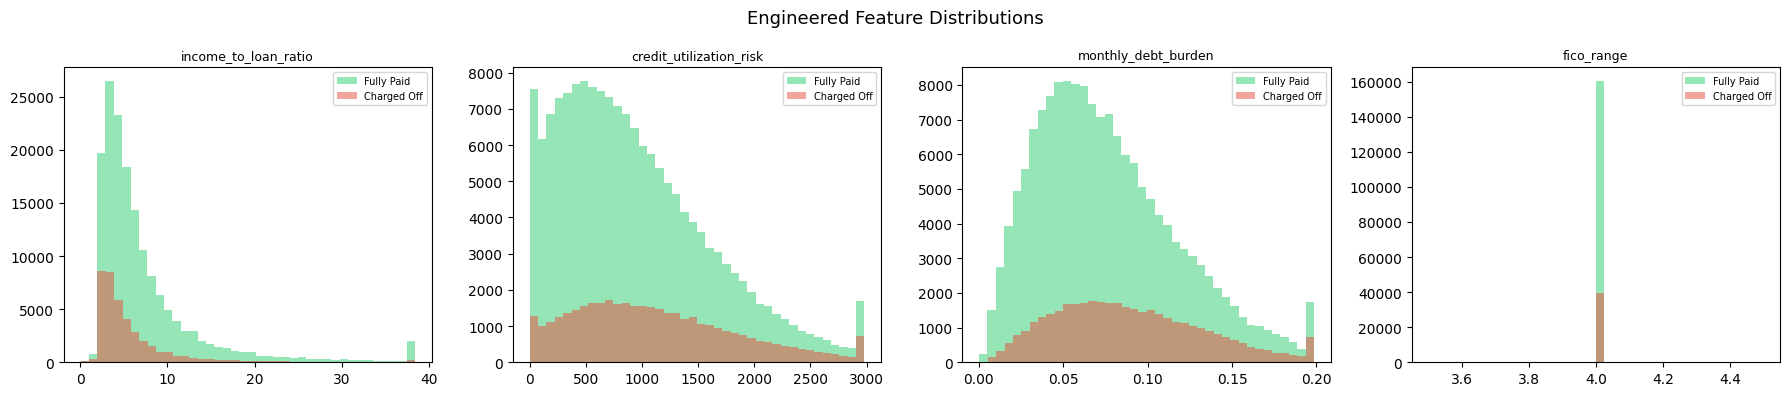

In [8]:
df['target'] = (df['loan_status'] == 'Charged Off').astype(int)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, eng_cols):
    paid  = df.loc[df['target']==0, col].clip(upper=df[col].quantile(0.99))
    choff = df.loc[df['target']==1, col].clip(upper=df[col].quantile(0.99))
    ax.hist(paid,  bins=40, alpha=0.5, color='#2ecc71', label='Fully Paid')
    ax.hist(choff, bins=40, alpha=0.5, color='#e74c3c', label='Charged Off')
    ax.set_title(col, fontsize=9)
    ax.legend(fontsize=7)
plt.suptitle('Engineered Feature Distributions', fontsize=13)
plt.tight_layout()
plt.show()

## 8. Final Feature Matrix Shape

In [9]:
ALL_FEATURES = [
    'loan_amnt','int_rate','installment','annual_inc','dti',
    'delinq_2yrs','fico_range_low','fico_range_high','open_acc','pub_rec',
    'revol_bal','revol_util','total_acc','mort_acc','pub_rec_bankruptcies',
    'purpose','home_ownership','verification_status','term',
    'grade','sub_grade','inq_last_6mths','emp_length','earliest_cr_line',
    'income_to_loan_ratio','credit_utilization_risk','monthly_debt_burden','fico_range'
]

X = df[ALL_FEATURES]
y = df['target']

print(f'Feature matrix X : {X.shape}')
print(f'Target vector  y : {y.shape}  |  default rate: {y.mean():.2%}')
print(f'\nFeatures ({len(ALL_FEATURES)}):')
for f in ALL_FEATURES:
    print(f'  {f}')

Feature matrix X : (199816, 28)
Target vector  y : (199816,)  |  default rate: 19.86%

Features (28):
  loan_amnt
  int_rate
  installment
  annual_inc
  dti
  delinq_2yrs
  fico_range_low
  fico_range_high
  open_acc
  pub_rec
  revol_bal
  revol_util
  total_acc
  mort_acc
  pub_rec_bankruptcies
  purpose
  home_ownership
  verification_status
  term
  grade
  sub_grade
  inq_last_6mths
  emp_length
  earliest_cr_line
  income_to_loan_ratio
  credit_utilization_risk
  monthly_debt_burden
  fico_range


In [10]:
# Verify no nulls in final matrix
null_check = X.isnull().sum().sum()
print(f'Null values in X: {null_check}  ✓' if null_check == 0 else f'WARNING: {null_check} nulls remain!')

Null values in X: 0  ✓
